# GaussianImage: Representing an image with 2D Gaussians

A single-file rewrite of the fitting part of
[GaussianImage](https://github.com/Xinjie-Q/GaussianImage) (ECCV 2024), extended with Beta and Gabor kernels.

**Files** (keep them next to this notebook):
- `gaussianimage.py`: models, both renderers, loss and helpers.
- `gi_render.cu`: the C++/CUDA forward and backward kernels.

**Two backends**, chosen in the Setup cell:

| | `"torch"` | `"cuda"` |
|---|---|---|
| Renderer | pure PyTorch, gradients by autograd | custom kernels in `gi_render.cu`, hand-written backward |
| Needs | nothing extra (runs on CPU or GPU) | GPU, `nvcc`, `ninja` (JIT-compiled once via `torch.utils.cpp_extension`) |
| Speed | slower; cost grows with the largest primitive | fast; each primitive costs only its own footprint |

- `BACKEND` sets the backend used during fitting and renders after training.
- `check_against_torch(kernel=...)` confirms that both backends give the same image and gradients for each kernel.

---

# Parameters

A model represents one image as `N` 2D primitives. Each primitive has **8 learnable numbers**, plus 0–3 for its kernel:

- **center** $(\mu_x, \mu_y)$: 2 numbers
- **covariance**: 3 numbers, in one of two forms (chosen by the model class)
  - `GaussianImage_Cholesky`: $(l_1, l_2, l_3)$ with $\Sigma = LL^\top$, where $L = \begin{bmatrix} l_1 & 0 \\ l_2 & l_3 \end{bmatrix}$
  - `GaussianImage_RS`: scales $(s_1, s_2)$ and angle $\theta$, with $\Sigma = (RS)(RS)^\top$
- **weighted color** $c' = (r', g', b')$: 3 numbers. Opacity is merged into the color (paper Eq. 7) and fixed at 1.
- **kernel parameters** (chosen by `kernel=`): none for `"gaussian"`, $b$ for `"beta"`, $(f_x, f_y, \phi)$ for `"gabor"`.

**Kernels.** Any kernel works with either covariance form; only the per-pixel weight changes. With $q = d^\top \Sigma^{-1} d$:
- `"gaussian"`: $w = \exp(-q/2)$
- `"beta"`: $w = (1-q)^{\beta}$ for $q \le 1$ (else 0), $\beta = 4e^{b}$ (Deformable Beta Splatting). $b = 0$ is Gaussian-like.
- `"gabor"`: $w = \exp(-q/2)\cos(2\pi f^\top d + \phi)$, a Gaussian envelope modulated by a wave of frequency $f$ and phase $\phi$.

# Rendering

1. **Map raw parameters into valid ranges.**
   - Centers: $\mu = \tanh(\text{raw})$, then scaled to pixel coordinates.
   - Cholesky: $l = \text{raw} + [0.5,\,0,\,0.5]$.
   - RS: $s = |\text{raw} + 0.5|$ and $\theta = 2\pi\,\sigma(\text{raw})$.
   - Beta: $\beta = 4e^{b}$. Gabor: $f = 0.5\tanh(\text{raw})$ cycles/px (at most Nyquist), $\phi = \text{raw}$.
2. **Covariance and conic.** Build $\Sigma$, then its inverse $\Sigma^{-1}$, in PyTorch for both backends.
3. **Footprint.** Each primitive gets its own radius $r = \lceil k\sqrt{\lambda_{\max}(\Sigma)} \rceil$, at least 2 px, with $k = 3$ ($k = 1$ for Beta, whose support ends at $q = 1$). It only touches pixels within that radius.
4. **Weight at each pixel $p$:** $w(p)$ from the kernel above, with $q = d^\top \Sigma^{-1} d$ and $d = p - \mu$.
5. **Accumulated sum** (no sorting, no occlusion, no background):
   $$C(p) = \sum_n c'_n\, w_n(p)$$
6. **Clamp the final image** to $[0, 1]$. Individual colors are never clamped, so primitives can go negative or above 1 to cancel each other and sharpen edges.

# Training

1. **Initialize.**
   - Centers uniform in $(-1, 1)$ via `atanh`.
   - Covariance, set by `init_scale`:
     - `None` (paper): $l_1, l_3$ (or $s_1, s_2$) in $0.5$–$1.5$ px.
     - $f$: the same range multiplied by $f \cdot \sqrt{HW/N}$ (a fraction of the spacing between primitives), so neighbours overlap from the first step. Colors are divided by $2\pi f^2$ so the first render isn't clamped.
     - Beta: either range is multiplied by $2\sqrt{2} \approx 2.83$, since $\Sigma$ marks the edge of its support; with $b = 0$ its footprint then matches a Gaussian's.
   - Colors uniform in $(0, 1)$.
   - Kernel parameters: Beta $b = 0$ ($\beta = 4$). Gabor: small random $f$ and $\phi = 0$, so it starts close to a Gaussian while $f$ and $\phi$ still receive gradients.
   - Optimizer: Adam with lr $10^{-3}$, halved every 20,000 steps.
   - $N$ stays fixed: no primitives are added or removed.
2. **Render** the full image.
3. **Loss:** $\text{MSE}(C, \text{gt})$, logged as $\text{PSNR} = 10 \log_{10}(1/\text{MSE})$.
4. **Backpropagate** with `loss.backward()`.
5. **Update** with `optimizer.step()` and `scheduler.step()`.
6. **Repeat.** The paper uses 50,000 steps. Snapshots for the progress video come from the training render, so they use `BACKEND`.

## 1. Setup

Installs dependencies, imports `gaussianimage.py`, and selects the training and rendering backends. If CUDA is selected, `gi_render.cu` compiles on the first run and is checked against PyTorch.

In [16]:
!pip install -q "imageio[ffmpeg]" ninja

# ---- imports ----
import os, sys, math, time, shutil, importlib

import numpy as np
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
import imageio_ffmpeg
from tqdm.auto import tqdm

sys.path.insert(0, os.getcwd())   # utils file sits next to this notebook
import gaussianimage
importlib.reload(gaussianimage)
from gaussianimage import MODELS, KERNELS, loss_fn, image_to_tensor, make_combined_video

mpl.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()

# ---- device ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch {torch.__version__} | device: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))

def sync():
    """Wait for the GPU (no-op on CPU); use around timings."""
    if device.type == "cuda":
        torch.cuda.synchronize()

# ---- backend ----
BACKEND = "cuda"   # "cuda" (C++/CUDA kernels) or "torch" (pure PyTorch)

if BACKEND == "cuda":
    assert device.type == "cuda", "CUDA backend needs a GPU; use 'torch'."
    assert shutil.which("nvcc"), "nvcc not found; install the CUDA toolkit or use 'torch'."
    gaussianimage.load_extension(verbose=True)   # compiles gi_render.cu (first run only)
    for k in KERNELS:
        gaussianimage.check_against_torch(kernel=k)   # each should print MATCH

Torch 2.6.0 | device: cuda (NVIDIA A10G)
[gaussian]
image      max abs err 9.537e-07   relative 1.946e-07
d_centers  max abs err 2.861e-06   relative 2.160e-07
d_cov      max abs err 2.995e-04   relative 9.410e-06
d_colors   max abs err 4.053e-06   relative 1.197e-07
MATCH
[beta]
image      max abs err 3.576e-07   relative 1.567e-07
d_centers  max abs err 5.722e-06   relative 2.665e-07
d_cov      max abs err 5.579e-05   relative 3.386e-06
d_colors   max abs err 1.192e-06   relative 1.146e-07
d_extra    max abs err 3.576e-07   relative 1.030e-07
MATCH
[gabor]
image      max abs err 1.192e-06   relative 4.647e-07
d_centers  max abs err 1.025e-05   relative 4.987e-07
d_cov      max abs err 2.069e-04   relative 8.852e-06
d_colors   max abs err 1.001e-05   relative 4.368e-07
d_extra    max abs err 2.441e-04   relative 3.737e-07
MATCH


Using /home/sagemaker-user/.cache/torch_extensions/py312_cu126 as PyTorch extensions root...
No modifications detected for re-loaded extension module gi_render_cuda, skipping build step...
Loading extension module gi_render_cuda...


## 2. Load the image

Set `IMAGE_PATH` to any image file. If it is `None`, the notebook uses the scikit-image demo image named in `DEMO_IMAGE`.

Image tensor: (1, 3, 512, 512)


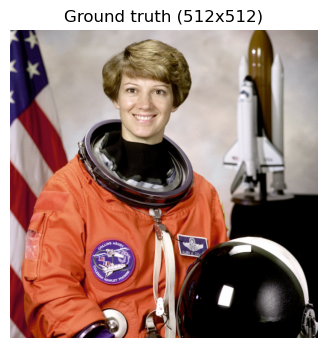

In [17]:
IMAGE_PATH = None           # e.g. "your_image.png"
DEMO_IMAGE = "astronaut"    # "astronaut" (RGB) or "camera" (grayscale)

if IMAGE_PATH is not None:
    source = IMAGE_PATH
else:
    from skimage import data as skdata
    source = getattr(skdata, DEMO_IMAGE)()

gt_image = image_to_tensor(source, device=device)
H, W = gt_image.shape[-2:]
print("Image tensor:", tuple(gt_image.shape))

plt.figure(figsize=(4, 4))
plt.imshow(gt_image[0].permute(1, 2, 0).cpu().numpy())
plt.title(f"Ground truth ({H}x{W})")
plt.axis("off")
plt.show()

## 3. Fit

The paper's Table 1 uses up to ~50,000 Gaussians and 50,000 steps on Kodak-sized images. Lower these settings for quicker runs.

In [18]:
NUM_POINTS = 10000
ITERATIONS = 50000
LR = 1e-3
DECOMPOSITION = "Cholesky"     # "Cholesky" or "RS"
KERNEL = "gabor"            # "gaussian", "beta" or "gabor"
SNAP_EVERY = 20
VERBOSE_EVERY = 1000
INIT_SCALE = 0.5     # None = paper (~1 px start); 0.5 = start at half the spacing

ModelClass = MODELS[DECOMPOSITION]
model = ModelClass(num_points=NUM_POINTS, H=H, W=W, device=device, lr=LR,
                   backend=BACKEND, init_scale=INIT_SCALE, kernel=KERNEL).to(device)

losses = torch.empty(ITERATIONS, device=device)
snapshots, snap_iters = [], []

sync(); t0 = time.time()
pbar = tqdm(range(1, ITERATIONS + 1), desc=f"{DECOMPOSITION}-{KERNEL}, {NUM_POINTS} primitives")
for it in pbar:
    image = model()["render"]
    loss = loss_fn(image, gt_image)
    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite loss at iter {it}.")
    loss.backward()
    model.optimizer.step()
    model.optimizer.zero_grad(set_to_none=True)
    model.scheduler.step()
    losses[it - 1] = loss.detach()

    if it == 1 or it % SNAP_EVERY == 0 or it == ITERATIONS:
        snapshots.append((image.detach()[0].permute(1, 2, 0) * 255).byte().cpu().numpy())
        snap_iters.append(it)
    if it % VERBOSE_EVERY == 0 or it == ITERATIONS:
        l = loss.item()
        pbar.set_postfix(loss=f"{l:.5f}", psnr=f"{10 * math.log10(1 / l):.2f} dB")
sync()
print(f"Fit time ({BACKEND}, {DECOMPOSITION}-{KERNEL}, {NUM_POINTS} primitives): {time.time() - t0:.1f} s")

loss_np = losses.cpu().numpy()
history = {"loss": loss_np.tolist(), "psnr": (10 * np.log10(1 / loss_np)).tolist(),
           "snapshot_iters": snap_iters, "snapshots": snapshots}

Cholesky-gaussian, 10000 primitives:   0%|          | 0/50000 [00:00<?, ?it/s]

Fit time (cuda, Cholesky-gaussian, 10000 primitives): 111.9 s


## 4. Model size

Compares the number of learnable parameters and their storage size with the raw 8-bit image.

In [19]:
params = [p for p in model.parameters() if p.requires_grad]
total_params = sum(p.numel() for p in params)
model_bytes = sum(p.numel() * p.element_size() for p in params)
image_bytes = H * W * 3

print(f"Learnable parameters: {total_params:,} ({total_params // NUM_POINTS} per primitive)")
print(f"Model size:           {model_bytes:,} bytes ({model_bytes / 1024:.1f} KB, {params[0].dtype})")
print(f"Raw image (8-bit):    {image_bytes:,} bytes ({image_bytes / 1024:.1f} KB)")
print(f"Model / image ratio:  {model_bytes / image_bytes:.2f}x")

Learnable parameters: 80,000 (8 per primitive)
Model size:           320,000 bytes (312.5 KB, torch.float32)
Raw image (8-bit):    786,432 bytes (768.0 KB)
Model / image ratio:  0.41x


## 5. Loss and PSNR

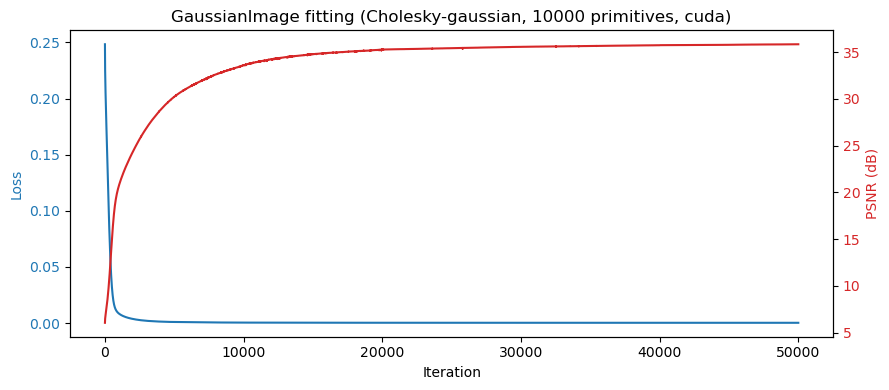

In [20]:
iters = np.arange(1, len(history["loss"]) + 1)

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()
for ax, key, label, color in ((ax1, "loss", "Loss", "tab:blue"),
                              (ax2, "psnr", "PSNR (dB)", "tab:red")):
    ax.plot(iters, history[key], color=color)
    ax.set_ylabel(label, color=color)
    ax.tick_params(axis="y", labelcolor=color)

ax1.set_xlabel("Iteration")
ax1.set_title(f"GaussianImage fitting ({DECOMPOSITION}-{KERNEL}, {model.init_num_points} primitives, {BACKEND})")
fig.tight_layout()
plt.show()

## 6. Ground truth vs. final reconstruction

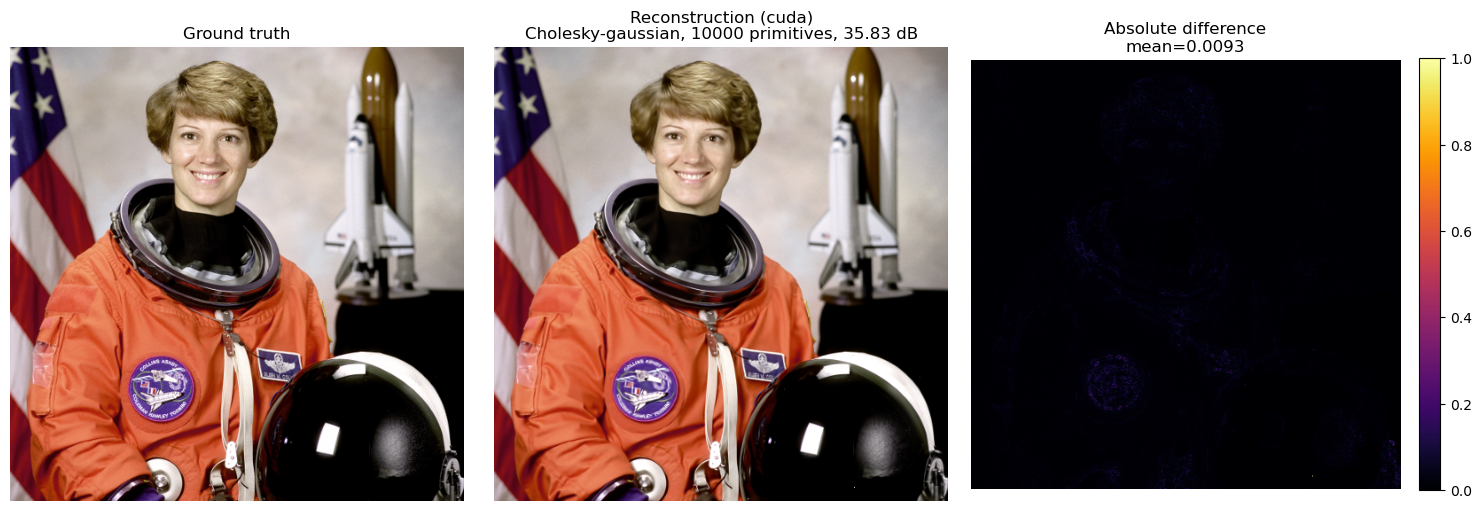

In [21]:
with torch.no_grad():
    final = model()["render"]
final_psnr = 10 * math.log10(1 / loss_fn(final, gt_image).item())

final_np = final[0].permute(1, 2, 0).cpu().numpy()
gt_np = gt_image[0].permute(1, 2, 0).cpu().numpy()
diff = np.abs(gt_np - final_np).mean(axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gt_np)
axes[0].set_title("Ground truth")
axes[1].imshow(final_np)
axes[1].set_title(f"Reconstruction ({BACKEND})\n{DECOMPOSITION}-{KERNEL}, {model.init_num_points} primitives, {final_psnr:.2f} dB")
im = axes[2].imshow(diff, cmap="inferno")
axes[2].set_title(f"Absolute difference\nmean={diff.mean():.4f}")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Render speed

In [22]:
for b in (["torch", "cuda"] if device.type == "cuda" else ["torch"]):
    with torch.no_grad():
        for _ in range(10):
            model(backend=b)
        sync(); t0 = time.perf_counter()
        for _ in range(100):
            model(backend=b)
        sync()
    print(f"{b:5s} render: {(time.perf_counter() - t0) * 10:.3f} ms/frame")

torch render: 101.436 ms/frame
cuda  render: 0.570 ms/frame


## 8. (Optional) Training progress video

In [23]:
def make_snapshot_video(history, out_path="training.mp4", fps=50, dpi=120):
    snapshots, snap_iters, psnr = history["snapshots"], history["snapshot_iters"], history["psnr"]

    fig, ax = plt.subplots(figsize=(4, 4.4))
    im = ax.imshow(snapshots[0])
    title = ax.set_title("", fontsize=11)
    ax.axis("off")
    plt.tight_layout()

    writer = FFMpegWriter(fps=fps, metadata={"title": "training"}, bitrate=4000)
    with writer.saving(fig, out_path, dpi=dpi):
        for frame, it in zip(snapshots, snap_iters):
            im.set_data(frame)
            title.set_text(f"it {it}  |  {psnr[it - 1]:.2f} dB")
            writer.grab_frame()

    plt.close(fig)
    print(f"Saved video to {out_path}")


make_snapshot_video(history, out_path=f"training_{BACKEND}_{DECOMPOSITION}-{KERNEL}_{NUM_POINTS}_init{INIT_SCALE}.mp4")

Saved video to training_cuda_Cholesky-gaussian_10000_initNone.mp4


## 9. Combined video for different numbers of Gaussians

In [26]:
NUM_POINTS_LIST = [200, 1000, 10000]
RUN_ITERATIONS = 30000
LR = 1e-3
RUN_SNAP_EVERY = 30
RUN_VERBOSE_EVERY = 1000
RUN_DECOMPOSITION = "Cholesky"     # "Cholesky" or "RS"
RUN_KERNEL = "gaussian"            # "gaussian", "beta" or "gabor"
INIT_SCALE = None               # None = paper (~1 px start); 0.5 = start at half the spacing

RunClass = MODELS[RUN_DECOMPOSITION]
models, histories = {}, {}

for n in NUM_POINTS_LIST:
    print(f"\n=== Fitting {RUN_DECOMPOSITION}-{RUN_KERNEL}, {n} primitives ===")
    m = RunClass(num_points=n, H=H, W=W, device=device, lr=LR,
                 backend=BACKEND, init_scale=INIT_SCALE, kernel=RUN_KERNEL).to(device)
    run_losses = torch.empty(RUN_ITERATIONS, device=device)
    run_snaps, run_iters = [], []

    sync(); t0 = time.time()
    pbar = tqdm(range(1, RUN_ITERATIONS + 1), desc=f"{RUN_DECOMPOSITION}-{RUN_KERNEL}, {n} primitives")
    for it in pbar:
        image = m()["render"]
        loss = loss_fn(image, gt_image)
        if not torch.isfinite(loss):
            raise RuntimeError(f"[{n} primitives] Non-finite loss at iter {it}.")
        loss.backward()
        m.optimizer.step()
        m.optimizer.zero_grad(set_to_none=True)
        m.scheduler.step()
        run_losses[it - 1] = loss.detach()

        if it == 1 or it % RUN_SNAP_EVERY == 0 or it == RUN_ITERATIONS:
            run_snaps.append((image.detach()[0].permute(1, 2, 0) * 255).byte().cpu().numpy())
            run_iters.append(it)
        if it % RUN_VERBOSE_EVERY == 0 or it == RUN_ITERATIONS:
            l = loss.item()
            pbar.set_postfix(loss=f"{l:.5f}", psnr=f"{10 * math.log10(1 / l):.2f} dB")
    sync()
    print(f"Fit time ({BACKEND}, {RUN_DECOMPOSITION}-{RUN_KERNEL}, {n} primitives): {time.time() - t0:.1f} s")

    loss_np = run_losses.cpu().numpy()
    histories[n] = {"loss": loss_np.tolist(), "psnr": (10 * np.log10(1 / loss_np)).tolist(),
                    "snapshot_iters": run_iters, "snapshots": run_snaps}
    models[n] = m


=== Fitting Cholesky-gaussian, 200 primitives ===


Cholesky-gaussian, 200 primitives:   0%|          | 0/30000 [00:00<?, ?it/s]

Fit time (cuda, Cholesky-gaussian, 200 primitives): 67.2 s

=== Fitting Cholesky-gaussian, 1000 primitives ===


Cholesky-gaussian, 1000 primitives:   0%|          | 0/30000 [00:00<?, ?it/s]

Fit time (cuda, Cholesky-gaussian, 1000 primitives): 67.5 s

=== Fitting Cholesky-gaussian, 10000 primitives ===


Cholesky-gaussian, 10000 primitives:   0%|          | 0/30000 [00:00<?, ?it/s]

Fit time (cuda, Cholesky-gaussian, 10000 primitives): 68.3 s


In [27]:
make_combined_video(
    histories, NUM_POINTS_LIST, gt_image,
    out_path=f"Nov_20_training_combined_{RUN_DECOMPOSITION}-{RUN_KERNEL}_{BACKEND}_"
             + "_".join(map(str, NUM_POINTS_LIST)) + f"_init{INIT_SCALE}.mp4",
    label="{} primitives",
)

Saved combined video to Nov_20_training_combined_Cholesky-gaussian_cuda_200_1000_10000_initNone.mp4


## 10. Kernel comparison: Gaussian vs. Beta vs. Gabor

Same number of primitives, initialization, optimizer and steps; only the kernel changes.

In [32]:
CMP_DECOMPOSITION = "Cholesky"     # "Cholesky" or "RS" (fixed for all runs)
CMP_KERNELS = ["gaussian", "beta", "gabor"]
CMP_POINTS = 500
LR = 1e-3
CMP_ITERATIONS = 30000
CMP_SNAP_EVERY = 30
CMP_VERBOSE_EVERY = 1000
CMP_INIT_SCALE = 0.5           # None = paper (~1 px start); 0.5 = start at half the spacing

CmpClass = MODELS[CMP_DECOMPOSITION]
cmp_models, cmp_histories = {}, {}

for kern in CMP_KERNELS:
    print(f"\n=== Fitting {CMP_DECOMPOSITION}-{kern}, {CMP_POINTS} primitives ===")
    torch.manual_seed(0)       # same centers, shapes and colors for every kernel
    m = CmpClass(num_points=CMP_POINTS, H=H, W=W, device=device, lr=LR,
                 backend=BACKEND, init_scale=CMP_INIT_SCALE, kernel=kern).to(device)
    run_losses = torch.empty(CMP_ITERATIONS, device=device)
    run_snaps, run_iters = [], []

    sync(); t0 = time.time()
    pbar = tqdm(range(1, CMP_ITERATIONS + 1), desc=f"{CMP_DECOMPOSITION}-{kern}, {CMP_POINTS} primitives")
    for it in pbar:
        image = m()["render"]
        loss = loss_fn(image, gt_image)
        if not torch.isfinite(loss):
            raise RuntimeError(f"[{kern}] Non-finite loss at iter {it}.")
        loss.backward()
        m.optimizer.step()
        m.optimizer.zero_grad(set_to_none=True)
        m.scheduler.step()
        run_losses[it - 1] = loss.detach()

        if it == 1 or it % CMP_SNAP_EVERY == 0 or it == CMP_ITERATIONS:
            run_snaps.append((image.detach()[0].permute(1, 2, 0) * 255).byte().cpu().numpy())
            run_iters.append(it)
        if it % CMP_VERBOSE_EVERY == 0 or it == CMP_ITERATIONS:
            l = loss.item()
            pbar.set_postfix(loss=f"{l:.5f}", psnr=f"{10 * math.log10(1 / l):.2f} dB")
    sync()

    n_params = sum(p.numel() for p in m.parameters())
    loss_np = run_losses.cpu().numpy()
    cmp_histories[kern] = {"loss": loss_np.tolist(), "psnr": (10 * np.log10(1 / loss_np)).tolist(),
                           "snapshot_iters": run_iters, "snapshots": run_snaps}
    cmp_models[kern] = m
    print(f"{kern}: {cmp_histories[kern]['psnr'][-1]:.2f} dB | {n_params // CMP_POINTS} params/primitive | "
          f"fit time ({BACKEND}): {time.time() - t0:.1f} s")



=== Fitting Cholesky-gaussian, 500 primitives ===


Cholesky-gaussian, 500 primitives:   0%|          | 0/30000 [00:00<?, ?it/s]

gaussian: 23.95 dB | 8 params/primitive | fit time (cuda): 67.3 s

=== Fitting Cholesky-beta, 500 primitives ===


Cholesky-beta, 500 primitives:   0%|          | 0/30000 [00:00<?, ?it/s]

beta: 23.18 dB | 9 params/primitive | fit time (cuda): 73.2 s

=== Fitting Cholesky-gabor, 500 primitives ===


Cholesky-gabor, 500 primitives:   0%|          | 0/30000 [00:00<?, ?it/s]

gabor: 24.98 dB | 11 params/primitive | fit time (cuda): 73.5 s


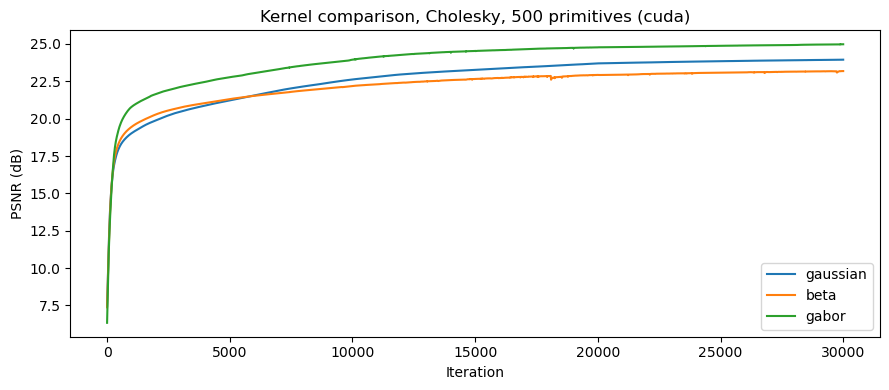

Saved combined video to Nov_20_raining_kernels_Cholesky_cuda_500_gaussian_beta_gabor_init0.5.mp4


In [33]:
# PSNR curves
fig, ax = plt.subplots(figsize=(9, 4))
for kern in CMP_KERNELS:
    ax.plot(cmp_histories[kern]["psnr"], label=kern)
ax.set(xlabel="Iteration", ylabel="PSNR (dB)",
       title=f"Kernel comparison, {CMP_DECOMPOSITION}, {CMP_POINTS} primitives ({BACKEND})")
ax.legend()
plt.tight_layout()
plt.show()

# Training video, one panel per kernel + ground truth
make_combined_video(
    cmp_histories, CMP_KERNELS, gt_image,
    out_path=f"Nov_20_raining_kernels_{CMP_DECOMPOSITION}_{BACKEND}_{CMP_POINTS}_" + "_".join(CMP_KERNELS)
             + f"_init{CMP_INIT_SCALE}.mp4",
    label=f"{{}}, {CMP_POINTS}",
)